### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [4]:
data = pd.read_csv('data/coupons.csv')

In [5]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [6]:
## Overview of Columns, Data Types, and Non-Null Counts
data.info()

## Count Missing Values per Column
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({'missing': missing, 'percent': missing_pct}).query('missing > 0').sort_values('missing', ascending=False)

## Check for Duplicate Rows
data.duplicated().sum()

## Look at the Unique Values in Each Text Column to Spot Odd Entries
for col in data.select_dtypes(include='object').columns:
    print(col, data[col].unique())

## Look for columns that never change
data.nunique().sort_values()

## Publish Results
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    'Column': missing.index,
    'Missing': missing.values,
    'Percent': (missing.values / len(data) * 100).round(1)
})

missing_table['Missing'] = missing_table.apply(
    lambda r: f"{r['Missing']:,} of {len(data):,} ({r['Percent']}%)", axis=1
)

missing_table = missing_table[['Column', 'Missing']]
missing_table.style.hide(axis='index')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

Column,Missing
car,"12,576 of 12,684 (99.1%)"
CoffeeHouse,"217 of 12,684 (1.7%)"
Restaurant20To50,"189 of 12,684 (1.5%)"
CarryAway,"151 of 12,684 (1.2%)"
RestaurantLessThan20,"130 of 12,684 (1.0%)"
Bar,"107 of 12,684 (0.8%)"


3. Decide what to do about your missing data -- drop, replace, other...

In [8]:
"""
Problem 3: Decide what to do about missing data -- drop, replace, other.
Dataset: coupons.csv (12,684 rows x 26 columns)

What's missing:
  car                   12,576  (99.15%)
  CoffeeHouse              217  (1.71%)
  Restaurant20To50         189  (1.49%)
  CarryAway                151  (1.19%)
  RestaurantLessThan20     130  (1.02%)
  Bar                      107  (0.84%)
  Everything else (including the target Y) is complete.

Decisions:
  1. DROP the `car` column. With 99% missing there is nothing to learn
     from it, and filling it would mean inventing almost the whole column.
  2. REPLACE gaps in the five frequency columns (Bar, CoffeeHouse,
     CarryAway, RestaurantLessThan20, Restaurant20To50) with each column's
     most common answer (mode). Why:
       - Only 605 rows (4.8%) have any gap, and each column is < 2% missing.
       - They are categorical survey answers ("never", "less1", "1~3", ...),
         so mean/median don't apply; the mode is the natural fill.
       - Rows with gaps accept coupons at about the same rate as the rest
         (55.0% vs 56.9%), so the missingness looks random and filling
         keeps those rows' other 24 columns of information.
  Alternative: dropping the 605 incomplete rows would also be defensible
  (see DROP_ROWS_INSTEAD below) since it only loses 4.8% of the data.
"""

import pandas as pd

TARGET = "Y"
DROP_ROWS_INSTEAD = False   # True = drop incomplete rows instead of filling

FREQ_COLS = ["Bar", "CoffeeHouse", "CarryAway",
             "RestaurantLessThan20", "Restaurant20To50"]

df = data.copy()
print(f"Starting from 'data': {df.shape[0]:,} rows x {df.shape[1]} columns\n")

# --- Inspect -------------------------------------------------------------
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values before cleaning:")
print(pd.DataFrame({"n_missing": missing,
                    "pct": (missing / len(df) * 100).round(2)}), "\n")

# Is missingness related to the target? (if so, it would be worth flagging)
has_gap = df[FREQ_COLS].isna().any(axis=1)
print(f"Rows with any frequency gap: {has_gap.sum()} ({has_gap.mean():.1%})")
print(f"Coupon acceptance (Y) -- rows with gaps: {df.loc[has_gap, TARGET].mean():.1%}, "
      f"complete rows: {df.loc[~has_gap, TARGET].mean():.1%}\n")

# --- 1. Drop the nearly empty column -----------------------------------
df = df.drop(columns=["car"])
print("Dropped column 'car' (99% missing)")

# --- 2. Replace (or drop) the frequency-column gaps ------------------------
if DROP_ROWS_INSTEAD:
    before = len(df)
    df = df.dropna(subset=FREQ_COLS)
    print(f"Dropped {before - len(df)} rows with missing frequency answers")
else:
    for col in FREQ_COLS:
        mode = df[col].mode()[0]
        n = df[col].isna().sum()
        df[col] = df[col].fillna(mode)
        print(f"Filled {n:>3} gaps in {col:<21} with mode '{mode}'")

# --- Verify --------------------------------------------------------------
remaining = int(df.isna().sum().sum())
assert remaining == 0, f"{remaining} missing values remain"
print(f"\nRemaining missing values: {remaining}")
print(f"Final shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

df.to_csv(OUT_PATH, index=False)
print(f"Saved {OUT_PATH}")

data = df  # carry the cleaned version forward to Problems 4+

Starting from 'data': 12,684 rows x 26 columns

Missing values before cleaning:
                      n_missing    pct
car                       12576  99.15
CoffeeHouse                 217   1.71
Restaurant20To50            189   1.49
CarryAway                   151   1.19
RestaurantLessThan20        130   1.02
Bar                         107   0.84 

Rows with any frequency gap: 605 (4.8%)
Coupon acceptance (Y) -- rows with gaps: 55.0%, complete rows: 56.9%

Dropped column 'car' (99% missing)
Filled 107 gaps in Bar                   with mode 'never'
Filled 217 gaps in CoffeeHouse           with mode 'less1'
Filled 151 gaps in CarryAway             with mode '1~3'
Filled 130 gaps in RestaurantLessThan20  with mode '1~3'
Filled 189 gaps in Restaurant20To50      with mode 'less1'

Remaining missing values: 0
Final shape: 12,684 rows x 25 columns
Saved coupons_clean.csv


4. What proportion of the total observations chose to accept the coupon?



In [9]:
## Problem 4: Proportion of all observations that accepted the coupon
accepted = data['Y'].sum()
total = len(data)
accept_rate = data['Y'].mean()

print(f"Accepted: {accepted:,} of {total:,}")
print(f"Acceptance rate: {accept_rate:.1%}")
print(f"Declined rate:   {1 - accept_rate:.1%}")

# Optional: breakdown table
data['Y'].value_counts(normalize=True).rename({1: 'Accepted', 0: 'Declined'}).round(3)

Accepted: 7,210 of 12,684
Acceptance rate: 56.8%
Declined rate:   43.2%


,proportion
Y,
Accepted,0.568
Declined,0.432


5. Use a bar plot to visualize the `coupon` column.

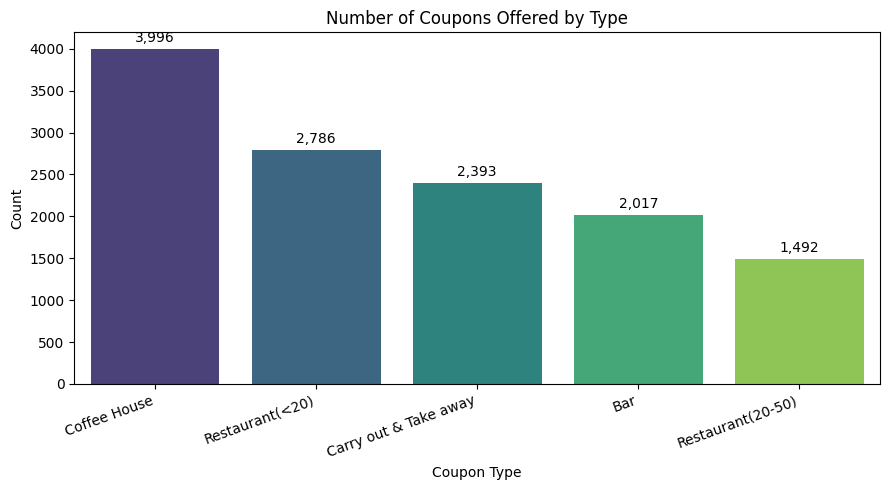

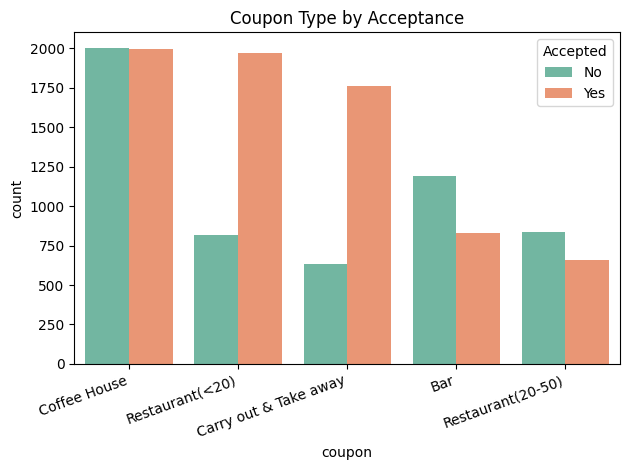

,count
coupon,
Coffee House,3996
Restaurant(<20),2786
Carry out & Take away,2393
Bar,2017
Restaurant(20-50),1492


In [12]:
## Problem 5: Bar plot of the coupon column
coupon_counts = data['coupon'].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=coupon_counts.index, y=coupon_counts.values,
            hue=coupon_counts.index, palette='viridis', legend=False, ax=ax)

# Put the count on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

ax.set_title('Number of Coupons Offered by Type')
ax.set_xlabel('Coupon Type')
ax.set_ylabel('Count')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

ax = sns.countplot(data=data, x='coupon', hue='Y',
                   order=coupon_counts.index, palette='Set2')
ax.legend(title='Accepted', labels=['No', 'Yes'])
ax.set_title('Coupon Type by Acceptance')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

coupon_counts

6. Use a histogram to visualize the temperature column.

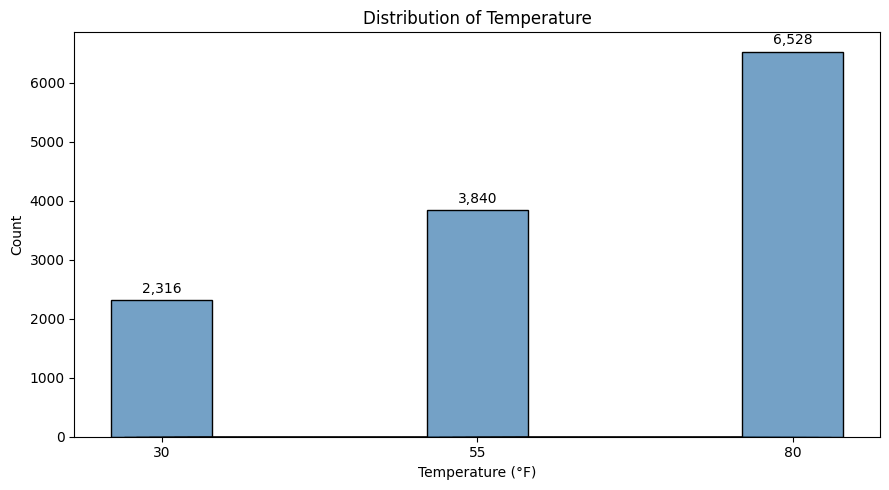

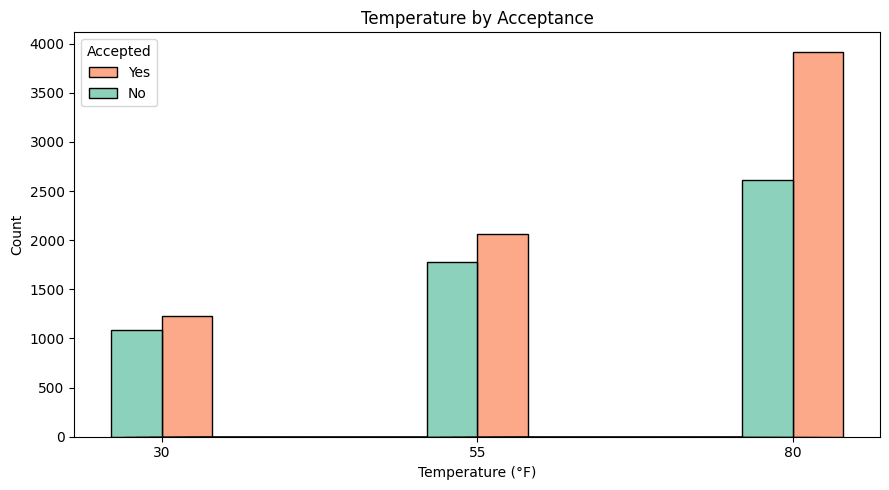

,count,acceptance_rate
temperature,,
30,2316,0.531
55,3840,0.537
80,6528,0.600


In [15]:
## Problem 6: Histogram of the temperature column
# Temperature only takes three values (30, 55, 80), so use discrete bins
# centered on each value instead of the default 10 continuous bins.

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=data, x='temperature', discrete=True, shrink=8,
             color='steelblue', ax=ax)

# Put the count on top of each bar
for container in ax.containers:
    labels = [f'{v:,.0f}' if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

ax.set_xticks(sorted(data['temperature'].unique()))
ax.set_title('Distribution of Temperature')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

# Same histogram, split by whether the coupon was accepted
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=data, x='temperature', hue='Y', discrete=True, shrink=8,
             multiple='dodge', palette='Set2', ax=ax)
ax.set_xticks(sorted(data['temperature'].unique()))
ax.legend(title='Accepted', labels=['Yes', 'No'])
ax.set_title('Temperature by Acceptance')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

# Counts and acceptance rate at each temperature
data.groupby('temperature')['Y'].agg(count='size', acceptance_rate='mean').round(3)

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


2. What proportion of bar coupons were accepted?


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  